The network in notebook.ipynb receives temperatures inside the domain. Without them, the equation and conditions must carry the solution into the interior.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
import torch
from torch import nn
from IPython.display import clear_output, display

In [3]:
# The analytical solution

alpha = 0.1
def u_exact(x,t):
    return np.sin(np.pi*x)*np.exp(-alpha*np.pi**2*t)

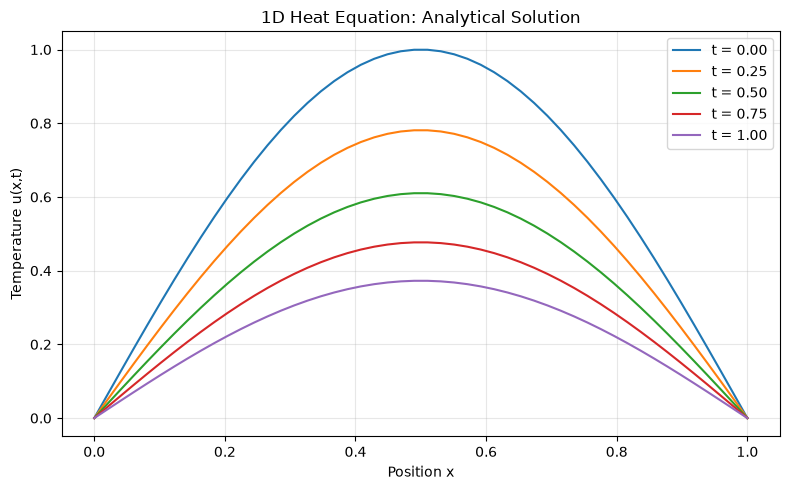

In [4]:
#Plotting the analytical solution

x = np.linspace(0, 1, 50)
times = [0.0, 0.25, 0.5, 0.75, 1.0]

plt.figure(figsize=(8,5))

for t in times:
    plt.plot(x, u_exact(x, t), label=f"t = {t:.2f}")
    
plt.xlabel("Position x")
plt.ylabel("Temperature u(x,t)")
plt.title("1D Heat Equation: Analytical Solution")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# sampling points

x_obs = rng.uniform(0, 1, size=(128, 1))
t_obs = rng.uniform(0, 1, size=(128, 1))

xt_obs = np.concatenate((x_obs, t_obs), axis=1)
u_obs = u_exact(x_obs, t_obs)

print(u_obs.shape)  # (128, 1)

print(xt_obs.shape)  # should be (128, 2)
print(xt_obs[:5])

(128, 1)
(128, 2)
[[0.77395605 0.10340297]
 [0.43887844 0.58764457]
 [0.85859792 0.17059297]
 [0.69736803 0.92512012]
 [0.09417735 0.58106114]]


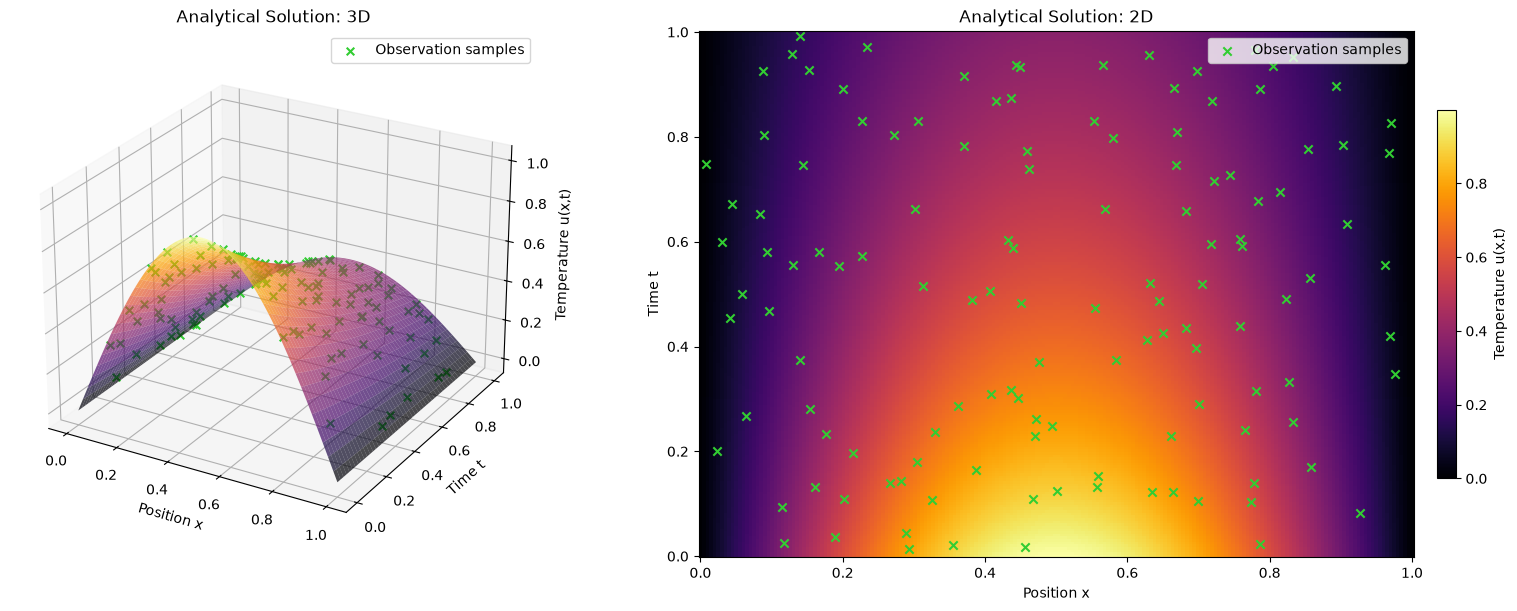

In [6]:
# plotting the sampled points on the analytical solution field

x = np.linspace(0, 1, 200)
t = np.linspace(0, 1, 200)
X, T = np.meshgrid(x, t)
U = u_exact(X, T)

fig = plt.figure(figsize=(16, 6), layout="constrained")

# 3D surface
ax1 = fig.add_subplot(1, 2, 1, projection="3d")

surface = ax1.plot_surface(X, T, U, cmap="inferno", alpha=0.7)
ax1.scatter(
    x_obs.ravel(),
    t_obs.ravel(),
    u_obs.ravel(),
    color="limegreen",
    marker="x",
    s=30,
    depthshade=False,
    label="Observation samples",
)

ax1.set_xlabel("Position x")
ax1.set_ylabel("Time t")
ax1.set_zlabel("Temperature u(x,t)")
ax1.set_title("Analytical Solution: 3D")
ax1.view_init(elev=25, azim=-60)
ax1.legend(loc="upper right")

# fig.colorbar(surface, ax=ax1, shrink=0.7, pad=0.1, label="Temperature u(x,t)")

# 2D field
ax2 = fig.add_subplot(1, 2, 2)

field = ax2.pcolormesh(X, T, U, shading="auto", cmap="inferno")
ax2.scatter(
    x_obs.ravel(),
    t_obs.ravel(),
    color="limegreen",
    marker="x",
    label="Observation samples",
)

ax2.set_xlabel("Position x")
ax2.set_ylabel("Time t")
ax2.set_title("Analytical Solution: 2D")
ax2.legend(loc="upper right")

fig.colorbar(field, ax=ax2, shrink=0.7, pad=0.02, label="Temperature u(x,t)")

plt.show()

In [7]:
## Sampling initial conditions

# rng = np.random.default_rng(42)

x_init = rng.uniform(0, 1, size=(64, 1))
t_init = np.zeros((64, 1)) #rng.uniform(0, 1, size=(128, 1))
u_init = np.sin(np.pi*x_init)

xt_init = np.concatenate((x_init, t_init), axis=1)
print(xt_init.shape)  # should be (64, 2)
print("(x_init, t_init) =", xt_init[:5])
print("u_init=", u_init[:5])

## Sampling left boundary conditions
# rng = np.random.default_rng(42)

x_leftBC = np.zeros((64,1)) # rng.uniform(0, 1, size=(64, 1))
t_leftBC = rng.uniform(0, 1, size=(64, 1))
u_leftBC = np.zeros((64,1))

xt_leftBC = np.concatenate((x_leftBC, t_leftBC), axis=1)
print(xt_leftBC.shape)  # should be (64, 2)
print("(x_leftBC, t_leftBC) =", xt_leftBC[:5])
print("u_leftBC=", u_leftBC[:5])


## Sampling right boundary conditions


x_rightBC = np.ones((64,1)) # rng.uniform(0, 1, size=(64, 1))
t_rightBC = rng.uniform(0, 1, size=(64, 1))
u_rightBC = np.zeros((64,1))

xt_rightBC = np.concatenate((x_rightBC, t_rightBC), axis=1)
print(xt_rightBC.shape)  # should be (64, 2)
print("(x_rightBC, t_rightBC) =", xt_rightBC[:5])
print("u_rightBC=", u_rightBC[:5])

(64, 2)
(x_init, t_init) = [[0.81656876 0.        ]
 [0.10527808 0.        ]
 [0.06655886 0.        ]
 [0.59443366 0.        ]
 [0.14617324 0.        ]]
u_init= [[0.54489696]
 [0.32474381]
 [0.20758039]
 [0.95631466]
 [0.44324617]]
(64, 2)
(x_leftBC, t_leftBC) = [[0.         0.91634802]
 [0.         0.48091043]
 [0.         0.32836121]
 [0.         0.53543479]
 [0.         0.84856049]]
u_leftBC= [[0.]
 [0.]
 [0.]
 [0.]
 [0.]]
(64, 2)
(x_rightBC, t_rightBC) = [[1.         0.37635947]
 [1.         0.98663154]
 [1.         0.71776024]
 [1.         0.95119466]
 [1.         0.11847858]]
u_rightBC= [[0.]
 [0.]
 [0.]
 [0.]
 [0.]]


In [8]:
## Sampling PDE collocation points


x_PDE = rng.uniform(0, 1, size=(1024, 1))
t_PDE = rng.uniform(0, 1, size=(1024, 1))


xt_PDE = np.concatenate((x_PDE, t_PDE), axis=1)
print(xt_PDE.shape)  # should be (64, 2)
print("(x_PDE, t_PDE) =", xt_PDE[:5])

(1024, 2)
(x_PDE, t_PDE) = [[0.05450031 0.10731236]
 [0.61630897 0.4976477 ]
 [0.04235055 0.5195496 ]
 [0.88414571 0.50819291]
 [0.70957829 0.43666749]]


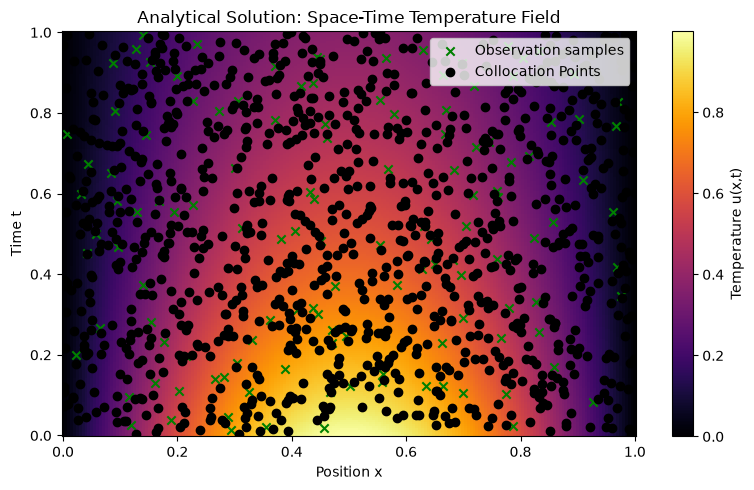

In [9]:
x = np.linspace(0, 1, 200)
t = np.linspace(0,1,200)

X, T = np.meshgrid(x,t)

U = u_exact(X, T)


plt.figure(figsize=(8,5))
plt.pcolormesh(X, T, U, shading="auto", cmap="inferno")

plt.colorbar(label="Temperature u(x,t)")

plt.scatter(x_obs, t_obs, c="green", marker="x", label="Observation samples")
plt.scatter(x_PDE, t_PDE, c="black", marker="o", label="Collocation Points")
plt.legend(loc="upper right")
plt.xlabel("Position x")
plt.ylabel("Time t")
plt.title("Analytical Solution: Space-Time Temperature Field")
plt.tight_layout()
plt.show()

In [10]:
#Converting to tensors

xt_obs_t = torch.tensor(xt_obs, dtype=torch.float32)
u_obs_t = torch.tensor(u_obs, dtype=torch.float32)

xt_PDE_t = torch.tensor(xt_PDE, dtype=torch.float32)
xt_PDE_t.requires_grad_(True)

xt_leftBC_t = torch.tensor(xt_leftBC, dtype=torch.float32)
xt_rightBC_t = torch.tensor(xt_rightBC, dtype=torch.float32)
xt_init_t = torch.tensor(xt_init, dtype=torch.float32)

u_leftBC_t = torch.tensor(u_leftBC, dtype=torch.float32)
u_rightBC_t = torch.tensor(u_rightBC, dtype=torch.float32)
u_init_t = torch.tensor(u_init, dtype=torch.float32)


In [20]:
torch.manual_seed(42)

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,1)
        )
        
    def forward(self, xt):
            return self.network(xt)

In [21]:
model = PINN()

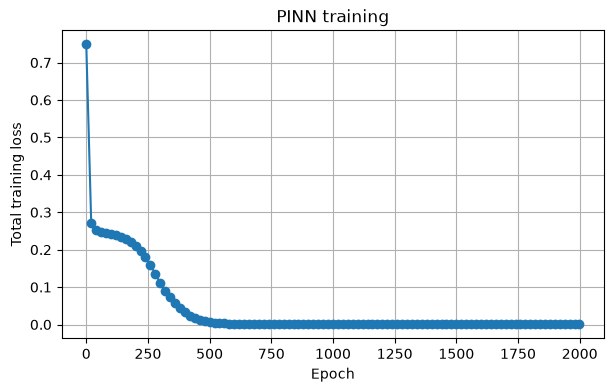

Epoch 1999 | Total: 0.0000 | PDE: 0.0000 | IC: 0.0000 | BC: 0.0000


In [22]:
# Training loop

optimizer1 = torch.optim.Adam(model.parameters(),
                             lr = 1e-3)

torch.manual_seed(42)
epochs = 2000
train_loss_values = []
test_loss_values = []
epoch_count = []

loss_components = {
    "PDE": [],    
    "Initial": [],
    "Boundary": [],
}
for epoch in range(epochs):
    model.train()   
    optimizer1.zero_grad()
    # 1. Predict temperature at the collocation points
    u_pred_PDE = model(xt_PDE_t)

    # 2. First derivatives with respect to x and t
    du_dxt = torch.autograd.grad(
        outputs=u_pred_PDE,
        inputs=xt_PDE_t,
        grad_outputs=torch.ones_like(u_pred_PDE),
        create_graph=True,
    )[0]

    u_x = du_dxt[:, 0:1]
    u_t = du_dxt[:, 1:2]

    # 3. Second derivative with respect to x
    dux_dxt = torch.autograd.grad(
        outputs=u_x,
        inputs=xt_PDE_t,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True,
    )[0]

    u_xx = dux_dxt[:, 0:1]

    # 4. Heat-equation residual
    residual_PDE = u_t - alpha * u_xx

    # Calculate all losses using the current model
    loss_PDE = torch.mean(residual_PDE**2)

    # residual_obs = model(xt_obs_t) - u_obs_t
    # loss_obs = torch.mean(residual_obs**2)

    residual_ic = model(xt_init_t) - u_init_t
    loss_ic = torch.mean(residual_ic**2)

    residual_leftBC = model(xt_leftBC_t) - u_leftBC_t
    loss_leftBC = torch.mean(residual_leftBC**2)

    residual_rightBC = model(xt_rightBC_t) - u_rightBC_t
    loss_rightBC = torch.mean(residual_rightBC**2)

    loss_BC = (loss_leftBC + loss_rightBC) / 2

    loss = loss_PDE + loss_ic + loss_BC

    loss.backward()

    loss_components["PDE"].append(loss_PDE.item())
    # loss_components["Observation"].append(loss_obs.item())
    loss_components["Initial"].append(loss_ic.item())
    loss_components["Boundary"].append(loss_BC.item())
    # 5. optim
    optimizer1.step()

    if epoch % 20 == 0 or epoch == epochs - 1:
        # Store the current loss as a regular Python number
        epoch_count.append(epoch)
        train_loss_values.append(loss.item())

        # Replace the previous output from this cell
        clear_output(wait=True)

        # Draw the loss history
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(epoch_count, train_loss_values, marker="o")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Total training loss")
        ax.set_title("PINN training")
        ax.grid(True)

        display(fig)
        plt.close(fig)

        print(
            f"Epoch {epoch:3d} | "
            f"Total: {loss.item():.4f} | "
            f"PDE: {loss_PDE.item():.4f} | "
            # f"Obs: {loss_obs.item():.4f} | "
            f"IC: {loss_ic.item():.4f} | "
            f"BC: {loss_BC.item():.4f}"
        )


        


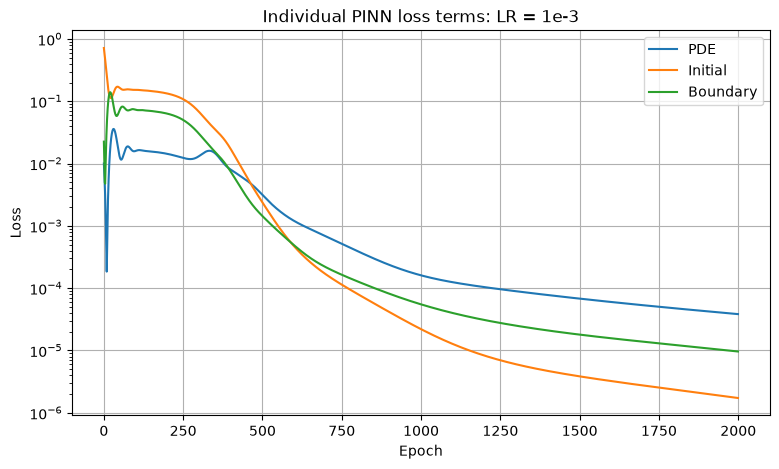

In [23]:
plt.figure(figsize=(9, 5))

for name, values in loss_components.items():
    plt.semilogy(values, label=name)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Individual PINN loss terms: LR = 1e-3")
plt.grid(True)
plt.legend()
plt.show()

In [24]:
# Turn the 200 × 200 grid into rows of (x, t) inputs
xt_grid = np.column_stack((X.ravel(), T.ravel()))

model.eval()
with torch.no_grad():
    xt_grid_t = torch.tensor(xt_grid, dtype=torch.float32)
    U_pred = model(xt_grid_t).cpu().numpy().reshape(U.shape)

relative_l2 = np.linalg.norm(U_pred - U) / np.linalg.norm(U)
print(f"Relative L2 error without observations: {relative_l2:.6f}")

Relative L2 error without observations: 0.003099
